# 🏭 Production Line Digital Twin — Part 2: Sensors & Breakdowns
Each machine now has:
- **Health** that drops with wear
- **Temperature & vibration sensors** (read every minute)
- **Random breakdowns** that get more likely as health drops
- **Defects** that get more likely as health drops

We simulate **10 shifts** and save 3 datasets: production log, sensor log, failure log.

### Imports
Same tools as Part 1.

In [36]:
import simpy
import random
import os
import pandas as pd
import matplotlib.pyplot as plt

### Settings
- $\text{SIM\_TIME} = 10 \times 8 \times 60 = 4800$ min
- Sensors are read every minute.
- A repair takes $\sim \text{Uniform}(20, 40)$ min.
- Same 4 stations and processing times as Part 1.

In [37]:
RANDOM_SEED = 42
SHIFTS = 10                      # simulate 10 shifts back to back
SIM_TIME = SHIFTS * 8 * 60       # 10 × 480 = 4800 minutes
ARRIVAL_INTERVAL = 5             # a new part arrives every ~5 minutes
SENSOR_INTERVAL = 1              # read the sensors every 1 minute

REPAIR_TIME_MIN = 20             # a repair takes between 20...
REPAIR_TIME_MAX = 40             # ...and 40 minutes

# Same line as Step 1: station name -> average processing time (minutes)
STATIONS = {
    "Cutting":    4,
    "Welding":    6,
    "Painting":   5,
    "Inspection": 3,
}

### The Machine class
Each machine tracks its own **health** (100 = new, 0 = worn out).

**Wear:** each part takes $\sim \text{Uniform}(0.5, 1.5)$ off health, about 1 point per part on average.

**Failure probability** after each part. It's cubic, so it stays tiny while healthy and rises fast when worn:
$$p_{fail} = 0.0005 + 0.2 \left(\frac{100 - h}{100}\right)^3$$

**Defect probability.** It's linear: 1% when new, 11% when fully worn:
$$p_{def} = 0.01 + 0.10 \cdot \frac{100 - h}{100}$$

| Health $h$ | 100 | 70 | 50 | 30 |
|---|---|---|---|---|
| $p_{fail}$ | 0.05% | 0.6% | 2.6% | 6.9% |
| $p_{def}$ | 1% | 4% | 6% | 8% |

In [38]:
class Machine:
    """
    A class is a blueprint. Each machine we create from it has its own
    name, health, status and counters, but they all share the same behaviour.
    """

    def __init__(self, env, name, avg_time):
        self.name = name
        self.avg_time = avg_time
        self.resource = simpy.Resource(env, capacity=1)   # the machine can handle 1 part at a time
        self.health = 100.0          # 100 = brand new, 0 = completely worn out
        self.status = "idle"         # "idle", "running" or "broken"

    def wear_out(self):
        """Every part processed wears the machine down a little."""
        self.health = max(self.health - random.uniform(0.5, 1.5), 0)   # health can't go below 0

    def failure_probability(self):
        """Chance of breaking after a part. Stays tiny while healthy, then rises FAST when worn
        (like real machines: they fail near the end of their life).
        health 100 -> 0.05%,  health 70 -> 0.6%,  health 50 -> 2.6%,  health 30 -> 6.9%"""
        return 0.0005 + ((100 - self.health) / 100) ** 3 * 0.2

    def defect_probability(self):
        """Chance of producing a bad part. Also grows as health drops.
        health 100 -> 1%,  health 0 -> 11%"""
        return 0.01 + (100 - self.health) / 100 * 0.10

### Sensor model
With $w = 100 - \text{health}$ (the amount of wear), the readings are:

| Status | Temperature (°C) | Vibration (mm/s) |
|---|---|---|
| running | $65 + 0.25w + \mathcal{N}(0, 1)$ | $1.5 + 0.04w + \mathcal{N}(0, 0.15)$ |
| idle | $45 + 0.10w + \mathcal{N}(0, 1)$ | $0.3 + 0.01w + \mathcal{N}(0, 0.05)$ |
| broken | $35 + \mathcal{N}(0, 1)$ | $\lvert\mathcal{N}(0, 0.02)\rvert$ |

$\mathcal{N}(0, \sigma)$ is Gaussian noise. A new running machine reads about 65 °C / 1.5 mm/s. At health 50 it reads about 77.5 °C / 3.5 mm/s.

In [39]:
def read_sensors(machine):
    """
    Creates realistic sensor readings from the machine's status and health.
    Rule of thumb: more wear = hotter + more vibration.
    random.gauss(0, x) adds a bit of noise, because real sensors are never perfectly smooth.
    """
    wear = 100 - machine.health       # 0 = new, 100 = worn out

    if machine.status == "running":
        temperature = 65 + wear * 0.25 + random.gauss(0, 1.0)    # °C
        vibration   = 1.5 + wear * 0.04 + random.gauss(0, 0.15)  # mm/s
    elif machine.status == "idle":
        temperature = 45 + wear * 0.10 + random.gauss(0, 1.0)
        vibration   = 0.3 + wear * 0.01 + random.gauss(0, 0.05)
    else:  # "broken": the machine is switched off for repair
        temperature = 35 + random.gauss(0, 1.0)
        vibration   = abs(random.gauss(0, 0.02))

    return round(temperature, 2), round(vibration, 3)

### Sensor monitor
A background process. Every minute it records status, health, temperature and vibration for all 4 machines.

Rows produced: $4800 \text{ min} \times 4 \text{ machines} = 19{,}200$.

In [40]:
def sensor_monitor(env, machines, logs):
    """Runs in the background, like an IoT system collecting data."""
    while True:
        for machine in machines.values():
            temperature, vibration = read_sensors(machine)
            logs["sensors"].append({
                "time":        env.now,
                "station":     machine.name,
                "status":      machine.status,
                "health":      round(machine.health, 2),
                "temperature": temperature,
                "vibration":   vibration,
            })
        yield env.timeout(SENSOR_INTERVAL)     # wait 1 minute, then read again

### Repair
Sets the machine to `broken`, logs the failure, waits $\sim \text{Uniform}(20, 40)$ min (mean 30), then resets health to 100.

In [41]:
def repair(env, machine, logs):
    """The machine is broken: stop, repair it, and reset its health."""
    machine.status = "broken"
    repair_time = random.uniform(REPAIR_TIME_MIN, REPAIR_TIME_MAX)

    logs["failures"].append({
        "station":       machine.name,
        "failure_time":  env.now,
        "repair_time":   repair_time,
        "health_before": round(machine.health, 2),
    })

    yield env.timeout(repair_time)     # the machine is out of action during the repair
    machine.health = 100.0             # repaired = as good as new

### The life of one part, with wear and breakdowns
At each station, after processing:
1. **Defect check:** `random.random() < p_def`, using the health *before* this part's wear.
2. **Wear:** health drops by about 1.
3. **Failure check:** with probability $p_{fail}$ the machine breaks and is repaired.

The part keeps hold of the machine during the repair, so the whole queue waits. That's how a breakdown causes downtime.

In [42]:
def part(env, part_id, machines, logs):
    for station_name in STATIONS:
        machine = machines[station_name]
        arrival_time = env.now

        with machine.resource.request() as request:
            yield request                          # wait in the queue
            start_time = env.now
            machine.status = "running"

            process_time = random.uniform(machine.avg_time * 0.8, machine.avg_time * 1.2)
            yield env.timeout(process_time)        # process the part

            # Was this part made badly? (a worn machine makes more mistakes)
            defect = random.random() < machine.defect_probability()
            machine.wear_out()                     # the machine gets a bit more worn

            # Does the machine break now?
            if random.random() < machine.failure_probability():
                # The machine keeps its 'request' during repair, so the queue has to WAIT
                yield env.process(repair(env, machine, logs))

            machine.status = "idle"
            end_time = env.now

        logs["production"].append({
            "part_id":      part_id,
            "station":      station_name,
            "arrival_time": arrival_time,
            "start_time":   start_time,
            "end_time":     end_time,
            "wait_time":    start_time - arrival_time,
            "process_time": process_time,
            "defect":       defect,
        })

### Part generator
Same as Part 1: exponential gaps with a mean of 5 min.

In [43]:
def part_generator(env, machines, logs):
    part_id = 0
    while True:
        yield env.timeout(random.expovariate(1 / ARRIVAL_INTERVAL))
        part_id += 1
        env.process(part(env, part_id, machines, logs))

### Run the simulation
Two processes run in parallel: the part generator and the sensor monitor. Each machine is a `Machine` object.

In [44]:
random.seed(RANDOM_SEED)
env = simpy.Environment()

# Create one Machine object per station
machines = {name: Machine(env, name, avg_time) for name, avg_time in STATIONS.items()}

# One dictionary holding our 3 logbooks
logs = {"production": [], "sensors": [], "failures": []}

env.process(part_generator(env, machines, logs))   # parts start arriving
env.process(sensor_monitor(env, machines, logs))   # sensors start recording
env.run(until=SIM_TIME)

print(f"Simulated {SHIFTS} shifts ({SIM_TIME} minutes)")
print(f"Production rows: {len(logs['production'])}")
print(f"Sensor rows:     {len(logs['sensors'])}")
print(f"Failures:        {len(logs['failures'])}")

Simulated 10 shifts (4800 minutes)
Production rows: 3207
Sensor rows:     19200
Failures:        53


### Convert logs to tables
Three DataFrames. `columns=` makes sure `failures` has the right columns even when it's empty.

In [45]:
production = pd.DataFrame(logs["production"])
sensors    = pd.DataFrame(logs["sensors"])
# 'columns=' makes sure the table has the right columns even if there were 0 failures
failures   = pd.DataFrame(logs["failures"],
                          columns=["station", "failure_time", "repair_time", "health_before"])

sensors.head(10)

,time,station,status,health,temperature,vibration
0,0,Cutting,idle,100.0,45.79,0.306
1,0,Welding,idle,100.0,45.27,0.381
2,0,Painting,idle,100.0,44.06,0.205
3,0,Inspection,idle,100.0,45.89,0.327
4,1,Cutting,idle,100.0,45.69,0.307
5,1,Welding,idle,100.0,44.77,0.300
6,1,Painting,idle,100.0,45.46,0.369
7,1,Inspection,idle,100.0,44.32,0.290
8,2,Cutting,idle,100.0,43.46,0.252
9,2,Welding,idle,100.0,46.81,0.304


### Failure log
One row per breakdown. `health_before` shows that breakdowns mostly happen when health is low.

In [46]:
failures.head(10)

,station,failure_time,repair_time,health_before
0,Cutting,260.053553,36.607447,54.21
1,Inspection,291.485090,36.347719,51.67
2,Welding,480.443178,39.728433,24.50
3,Painting,552.042942,25.253540,21.49
4,Cutting,668.865605,25.622690,10.84
5,Inspection,773.530554,30.271308,28.95
6,Welding,875.055871,24.322709,39.50
7,Cutting,923.740933,21.107131,50.29
8,Painting,946.100326,29.446583,34.45
9,Cutting,1054.225396,35.091205,73.86


### Per-station summary
- `downtime_min` $= \sum$ repair times
- $\text{defect rate (\%)} = \text{mean}(\text{defect}) \times 100$. `True` counts as 1 and `False` as 0, so the mean is the share of defects.

`fillna(0)` puts 0 for stations with no failures.

In [47]:
summary = pd.DataFrame(index=list(STATIONS.keys()))   # one row per station, in line order

summary["parts_processed"] = production.groupby("station").size()
summary["failures"]        = failures.groupby("station").size()
summary["downtime_min"]    = failures.groupby("station")["repair_time"].sum()
summary["defect_rate_%"]   = production.groupby("station")["defect"].mean() * 100

summary = summary.fillna(0).round(1)    # stations with no failures get 0 instead of empty
summary

,parts_processed,failures,downtime_min,defect_rate_%
Cutting,972,16,462.9,3.6
Welding,746,11,298.3,5.6
Painting,745,13,372.9,4.4
Inspection,744,13,390.6,3.6


### Health and sensors over time (Welding, first 2 shifts)
Three stacked charts on the same time axis, with a red dashed line at every breakdown.

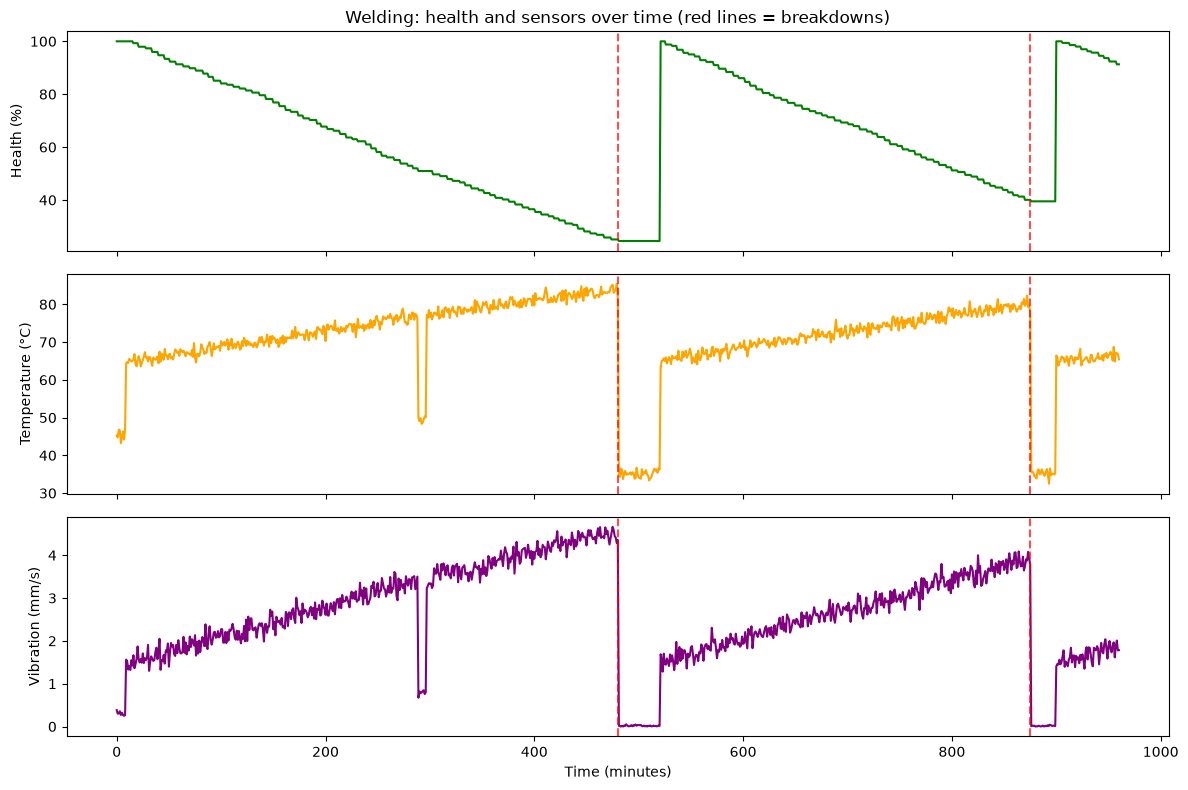

In [48]:
station = "Welding"     # try other stations too!
window = 960            # show the first 2 shifts only, so the chart is readable

s = sensors[(sensors["station"] == station) & (sensors["time"] <= window)]
f = failures[(failures["station"] == station) & (failures["failure_time"] <= window)]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)   # 3 charts stacked, same time axis

axes[0].plot(s["time"], s["health"], color="green")
axes[0].set_ylabel("Health (%)")
axes[0].set_title(f"{station}: health and sensors over time (red lines = breakdowns)")

axes[1].plot(s["time"], s["temperature"], color="orange")
axes[1].set_ylabel("Temperature (°C)")

axes[2].plot(s["time"], s["vibration"], color="purple")
axes[2].set_ylabel("Vibration (mm/s)")
axes[2].set_xlabel("Time (minutes)")

# Draw a red dashed line at every breakdown, on all 3 charts
for ax in axes:
    for t in f["failure_time"]:
        ax.axvline(t, color="red", linestyle="--", alpha=0.7)

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/02_sensors_before_failure.png", dpi=120)
plt.show()

key result. Health drops like a sawtooth, and temperature and vibration slowly rise as health falls. Then comes a red line (breakdown), the sensors drop, and health jumps back to 100%.

### Breakdowns and downtime per station

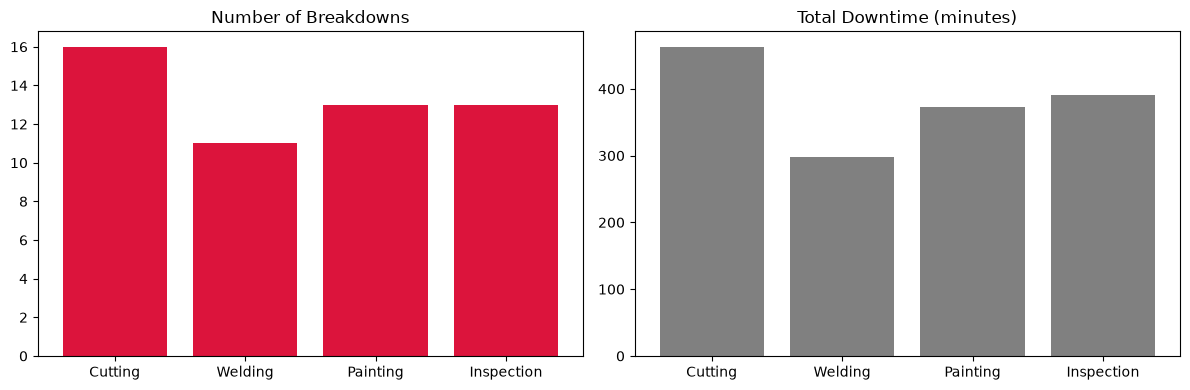

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(summary.index, summary["failures"], color="crimson")
axes[0].set_title("Number of Breakdowns")

axes[1].bar(summary.index, summary["downtime_min"], color="gray")
axes[1].set_title("Total Downtime (minutes)")

plt.tight_layout()
plt.savefig("../images/02_failures_downtime.png", dpi=120)
plt.show()

### Save the datasets
These three CSVs are the input for Parts 3 and 5.

In [50]:
os.makedirs("../data", exist_ok=True)
production.to_csv("../data/production_log.csv", index=False)
sensors.to_csv("../data/sensor_log.csv", index=False)
failures.to_csv("../data/failure_log.csv", index=False)
print("Saved production_log.csv, sensor_log.csv, failure_log.csv 💾")

Saved production_log.csv, sensor_log.csv, failure_log.csv 💾


## 📝 Conclusions
- Over 10 shifts the line produced 3,207 station records and 19,200 sensor readings, and had **53 breakdowns**.
- **Cutting broke down most often** (16 times, 463 min downtime). It processes the most parts (972), so it wears out fastest.
- **Welding has the highest defect rate (5.6%).** It runs at the lowest average health (67%), and a worn machine makes more defects.
- In the sensor chart, temperature and vibration rise as health drops, then fall after each breakdown and repair. That warning pattern is what Part 5 uses to predict failures.